# 02 · Image preprocessing

Old scans arrive with bleed-through from the reverse side, paper texture, faint ink and skew.
Preprocessing turns each page into something close to black text on white paper before any
model sees it. Everything here calls the app's own operations (`backend/preprocessing`), so
what you see is exactly what the app does.

1. What each of the 10 operations does
2. Why there is no single best pipeline (Otsu vs Sauvola on bleed-through)
3. Piecewise deskew for pages that are straight at the top but tilted near the spine
4. The recipe we use for PORCONES books

In [1]:
# Make experimentation/src importable (this also puts backend/ on sys.path, so the
# notebooks run the app's own preprocessing, detection and recognition code).
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
%matplotlib inline

In [2]:
from src import figures
from preprocessing.operations import OP_REGISTRY
print(f"{len(OP_REGISTRY)} operations:", ", ".join(OP_REGISTRY))

10 operations: normalize, grayscale, deskew, denoise, contrast, sharpen, threshold, morph, remove_blobs, remove_noise


## 1. Every operation on the same crop

The crop has real text, ghost text bleeding through from the reverse side, and paper texture.

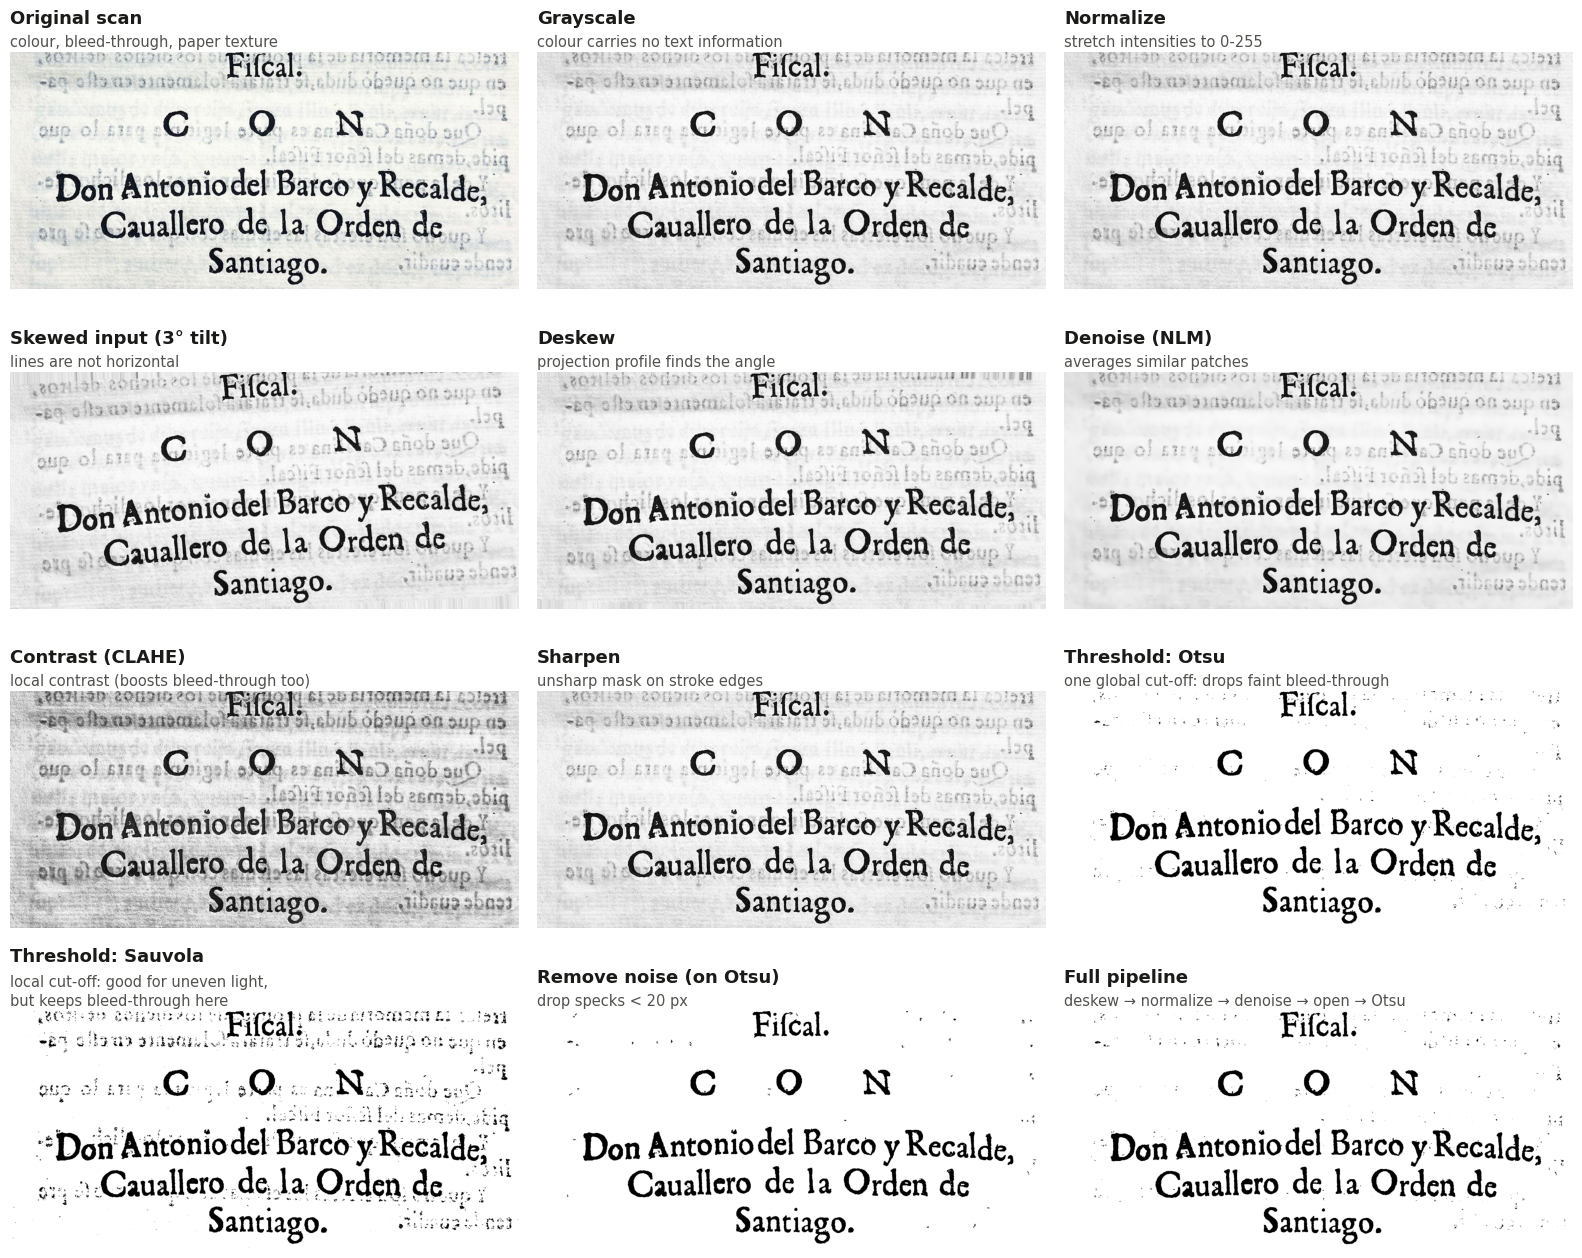

In [3]:
figures.preprocessing_grid();

## 2. No pipeline fits every book

On this page the bleed-through is lighter than real ink everywhere, so **Otsu** (one global
cut-off) removes it cleanly. **Sauvola** (a cut-off per neighbourhood) is normally the better
choice for uneven lighting, but here it keeps the ghost text, and CLAHE makes it stronger.
That is why the app lets the user tune the pipeline with a live preview, and offers tested
presets per book type.

## 3. Piecewise deskew

A single rotation cannot fix a page that is straight at the top but tilted near the spine.
Deskew measures the angle in horizontal bands (rotate a little, count ink per row: at the
right angle the rows alternate sharply between full lines and gaps). If the bands agree it
rotates once; otherwise it rotates each band by its own angle and blends neighbours with
weights that sum to 1, so no seam is visible. Below, the lower half of the crop is tilted by
3° to simulate a warped page.

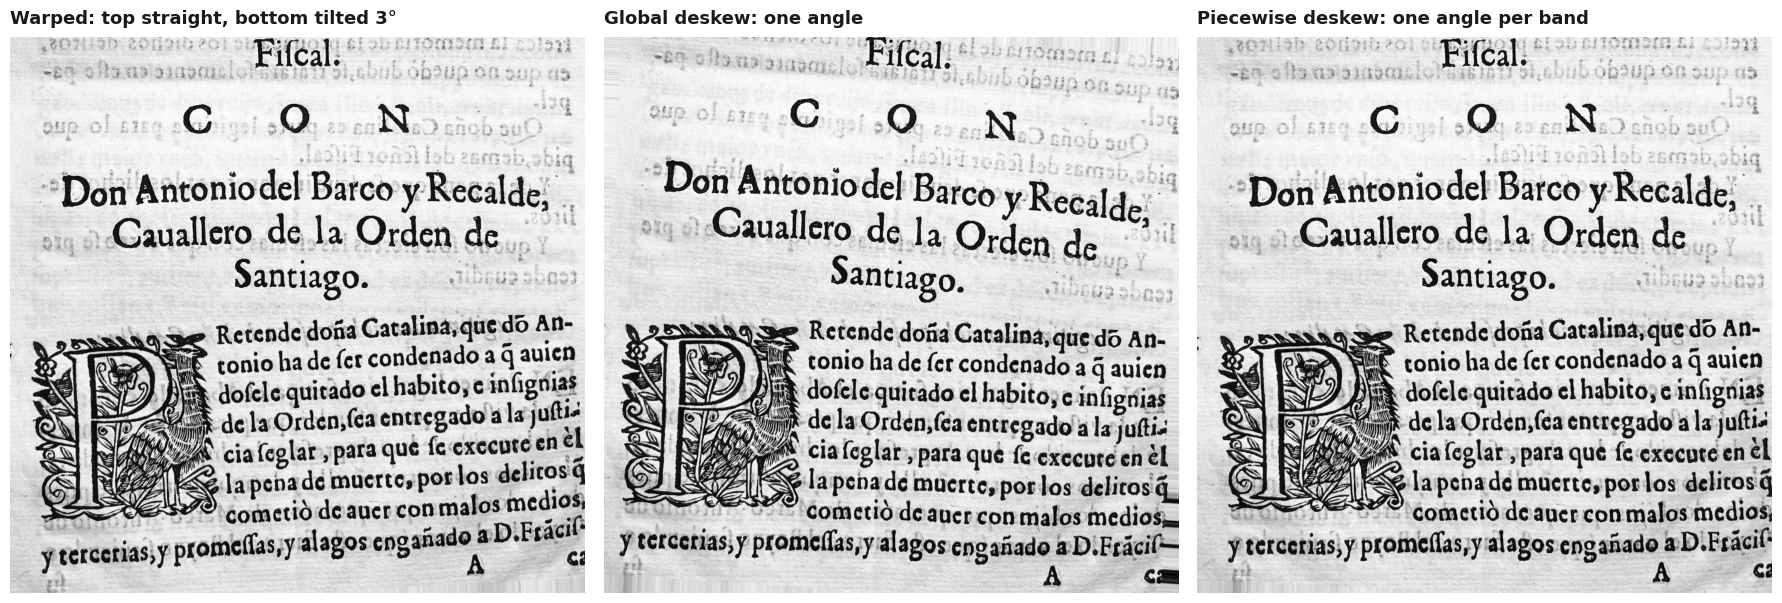

In [4]:
import cv2, numpy as np, matplotlib.pyplot as plt

page = cv2.imread(figures.PAGE, cv2.IMREAD_GRAYSCALE)[1860:3600, 650:2450]
h, w = page.shape
tilted = cv2.warpAffine(page, cv2.getRotationMatrix2D((w / 2, h * 0.75), 3, 1.0), (w, h),
                        borderMode=cv2.BORDER_REPLICATE)
warped = np.vstack([page[: h // 2], tilted[h // 2:]])  # straight top, tilted bottom

fig, axes = plt.subplots(1, 3, figsize=(18, 7))
for ax, img, title in [(axes[0], warped, "Warped: top straight, bottom tilted 3°"),
                       (axes[1], OP_REGISTRY["deskew"](warped, {"mode": "global"}), "Global deskew: one angle"),
                       (axes[2], OP_REGISTRY["deskew"](warped, {"mode": "piecewise", "bands": 6}),
                        "Piecewise deskew: one angle per band")]:
    ax.imshow(img, cmap="gray"); ax.set_title(title); ax.axis("off")
plt.tight_layout()

## 4. The PORCONES recipe

`grayscale → deskew → normalize → denoise (NLM) → morphological open → Otsu threshold`.
It is defined once in `src/evaluation.py` and used by the detection notebook, the evaluation
script and the README figures. Notebook 04 measures what it does to full-page accuracy.

{'op': 'grayscale'}
{'op': 'deskew', 'params': {'mode': 'auto'}}
{'op': 'normalize', 'params': {'strength': 100}}
{'op': 'denoise', 'params': {'method': 'nlm', 'strength': 10}}
{'op': 'morph', 'params': {'operation': 'open', 'kernelSize': 2, 'kernelShape': 'rect', 'iterations': 2}}
{'op': 'threshold', 'params': {'method': 'otsu'}}


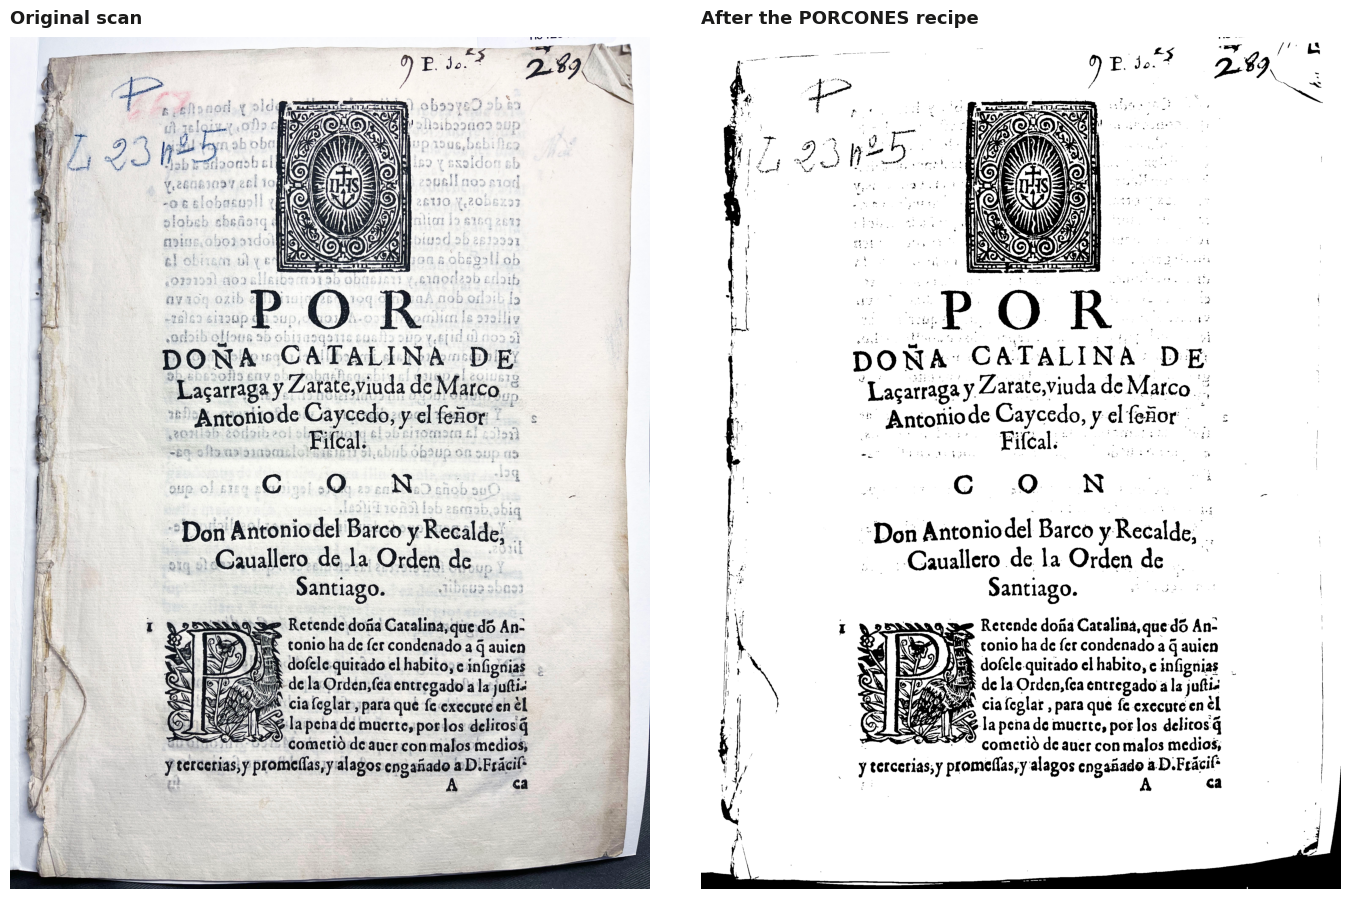

In [5]:
from src.evaluation import CLEAN
from preprocessing import run_pipeline

for step in CLEAN:
    print(step)
full = cv2.imread(figures.PAGE)
cleaned = run_pipeline(full, CLEAN).image
fig, axes = plt.subplots(1, 2, figsize=(14, 9))
axes[0].imshow(figures.rgb(full)); axes[0].set_title("Original scan")
axes[1].imshow(cleaned, cmap="gray"); axes[1].set_title("After the PORCONES recipe")
for ax in axes: ax.axis("off")
plt.tight_layout()